In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("../data/processed/african_economic_indicators.csv")

df.head()

,country,country_code,indicator_code,indicator,year,value,unit
0,"Egypt, Arab Rep.",EGY,PA.NUS.FCRF,exchange_rate,2000,3.472050,Local currency units per USD
1,"Egypt, Arab Rep.",EGY,PA.NUS.FCRF,exchange_rate,2001,3.973000,Local currency units per USD
2,"Egypt, Arab Rep.",EGY,PA.NUS.FCRF,exchange_rate,2002,4.499667,Local currency units per USD
3,"Egypt, Arab Rep.",EGY,PA.NUS.FCRF,exchange_rate,2003,5.850875,Local currency units per USD
4,"Egypt, Arab Rep.",EGY,PA.NUS.FCRF,exchange_rate,2004,6.196242,Local currency units per USD


In [6]:
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1040, 7)

Data types:
country            object
country_code       object
indicator_code     object
indicator          object
year                int64
value             float64
unit               object
dtype: object

Missing values:
country            0
country_code       0
indicator_code     0
indicator          0
year               0
value             25
unit               0
dtype: int64


In [7]:
coverage = (
    df.groupby(["country", "indicator"])["value"]
    .count()
    .reset_index(name="available_years")
)

print(coverage.to_string(index=False))

         country      indicator  available_years
Egypt, Arab Rep.  exchange_rate               26
Egypt, Arab Rep.     gdp_growth               26
Egypt, Arab Rep. gdp_per_capita               26
Egypt, Arab Rep.      inflation               26
Egypt, Arab Rep. internet_users               25
Egypt, Arab Rep.      oil_rents               22
Egypt, Arab Rep.     population               26
Egypt, Arab Rep.   unemployment               26
           Ghana  exchange_rate               26
           Ghana     gdp_growth               26
           Ghana gdp_per_capita               26
           Ghana      inflation               26
           Ghana internet_users               25
           Ghana      oil_rents               22
           Ghana     population               26
           Ghana   unemployment               26
           Kenya  exchange_rate               26
           Kenya     gdp_growth               26
           Kenya gdp_per_capita               26
           Kenya    

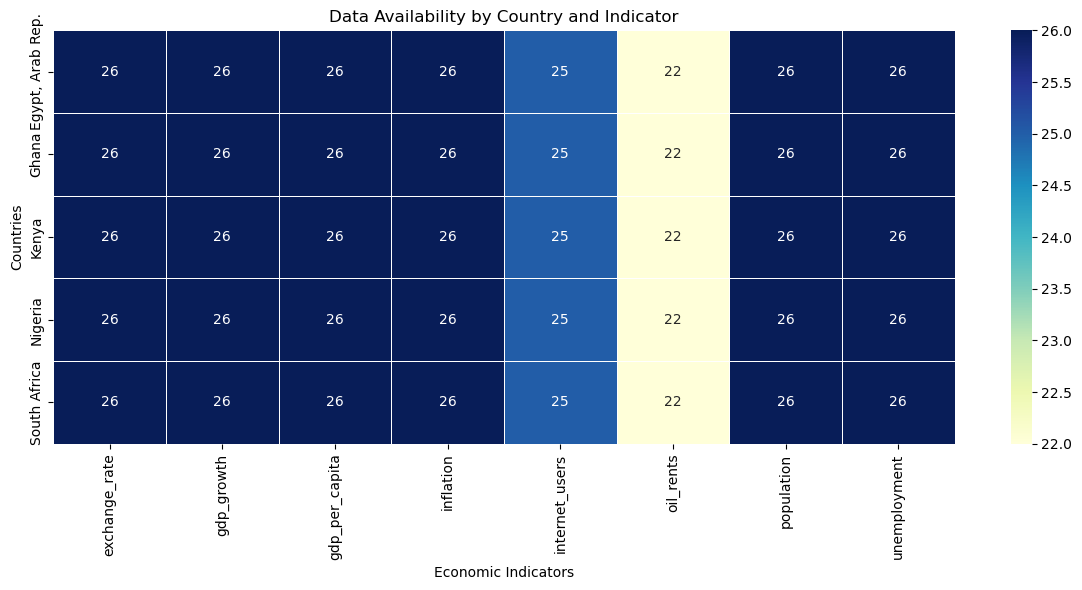

In [8]:
coverage_pivot = coverage.pivot(
    index="country",
    columns="indicator",
    values="available_years"
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    coverage_pivot,
    annot=True,
    cmap="YlGnBu",
    linewidths=0.5,
    fmt=".0f"
)

plt.title("Data Availability by Country and Indicator")
plt.xlabel("Economic Indicators")
plt.ylabel("Countries")
plt.tight_layout()
plt.show()

In [9]:
gdp_growth = df[df["indicator"] == "gdp_growth"].copy()

gdp_growth.head()

,country,country_code,indicator_code,indicator,year,value,unit
26,"Egypt, Arab Rep.",EGY,NY.GDP.MKTP.KD.ZG,gdp_growth,2000,6.370004,Percentage (%)
27,"Egypt, Arab Rep.",EGY,NY.GDP.MKTP.KD.ZG,gdp_growth,2001,3.535252,Percentage (%)
28,"Egypt, Arab Rep.",EGY,NY.GDP.MKTP.KD.ZG,gdp_growth,2002,2.390204,Percentage (%)
29,"Egypt, Arab Rep.",EGY,NY.GDP.MKTP.KD.ZG,gdp_growth,2003,3.193455,Percentage (%)
30,"Egypt, Arab Rep.",EGY,NY.GDP.MKTP.KD.ZG,gdp_growth,2004,4.092072,Percentage (%)


In [13]:
gdp_growth_summary = (
    gdp_growth.groupby("country")["value"]
    .agg(["mean", "min", "max", "std"])
    .reset_index()
)

print(gdp_growth_summary.sort_values("mean", ascending=False))

            country      mean       min        max       std
1             Ghana  5.604524  0.513942  14.047124  2.712907
3           Nigeria  4.758004 -6.368898  15.329156  3.977687
2             Kenya  4.356553 -0.272766   8.058474  2.144017
0  Egypt, Arab Rep.  4.300649  1.764572   7.156284  1.594612
4      South Africa  2.179486 -6.168918   5.603806  2.468911


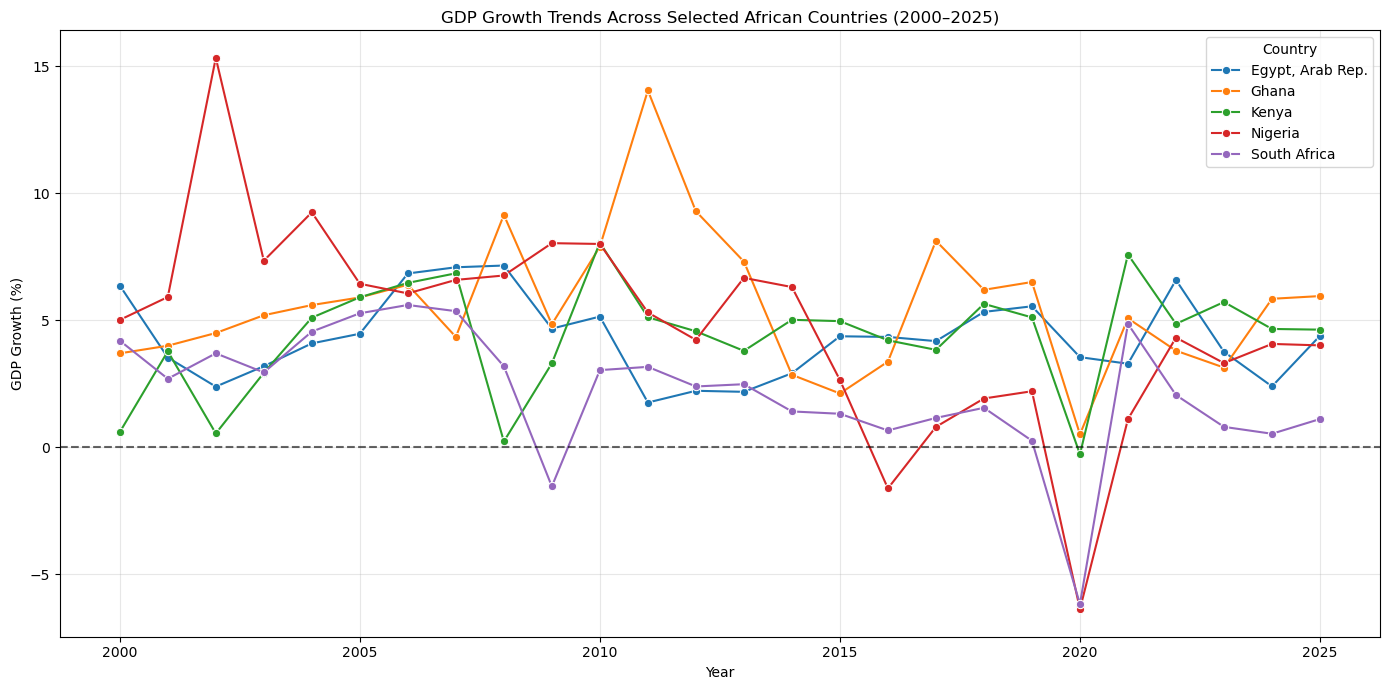

In [14]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=gdp_growth,
    x="year",
    y="value",
    hue="country",
    marker="o"
)

plt.title("GDP Growth Trends Across Selected African Countries (2000–2025)")
plt.xlabel("Year")
plt.ylabel("GDP Growth (%)")

plt.axhline(0, linestyle="--", color="black", alpha=0.6)

plt.legend(title="Country")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
def calculate_indicator_statistics(data, indicator_name):

    indicator_data = data[
        (data["indicator"] == indicator_name) &
        (data["value"].notna())
    ].copy()

    results = []

    for country, group in indicator_data.groupby("country"):

        group = group.sort_values("year")

        min_row = group.loc[group["value"].idxmin()]
        max_row = group.loc[group["value"].idxmax()]

        first_row = group.iloc[0]
        last_row = group.iloc[-1]

        results.append({
            "country": country,
            "observations": group["value"].count(),
            "mean": group["value"].mean(),
            "median": group["value"].median(),
            "std": group["value"].std(),
            "minimum": min_row["value"],
            "minimum_year": min_row["year"],
            "maximum": max_row["value"],
            "maximum_year": max_row["year"],
            "first_year": first_row["year"],
            "first_value": first_row["value"],
            "last_year": last_row["year"],
            "last_value": last_row["value"],
            "absolute_change": last_row["value"] - first_row["value"]
        })

    return pd.DataFrame(results)

In [22]:
inflation_summary = calculate_indicator_statistics(
    df, "gdp_growth"
)

print(
    inflation_summary.round(2).to_string(index=False)
)
inflation_summary = calculate_indicator_statistics(
    df, "inflation"
)

print(
    inflation_summary.round(2).to_string(index=False)
)
gdp_per_capita_summary = calculate_indicator_statistics(
    df, "gdp_per_capita"
)

print(
    gdp_per_capita_summary.round(2).to_string(index=False)
)
unemployment_summary = calculate_indicator_statistics(
    df, "unemployment"
)

print(
    unemployment_summary.round(2).to_string(index=False)
)
internet_summary = calculate_indicator_statistics(
    df, "internet_users"
)

print(
    internet_summary.round(2).to_string(index=False)
)
population_summary = calculate_indicator_statistics(
    df, "population"
)

print(
    population_summary.round(2).to_string(index=False)
)
exchange_rate_summary = calculate_indicator_statistics(
    df, "exchange_rate"
)

print(
    exchange_rate_summary.round(2).to_string(index=False)
)
oil_rents_summary = calculate_indicator_statistics(
    df, "oil_rents"
)

print(
    oil_rents_summary.round(2).to_string(index=False)
)

         country  observations  mean  median  std  minimum  minimum_year  maximum  maximum_year  first_year  first_value  last_year  last_value  absolute_change
Egypt, Arab Rep.            26  4.30    4.26 1.59     1.76          2011     7.16          2008        2000         6.37       2025        4.39            -1.98
           Ghana            26  5.60    5.40 2.71     0.51          2020    14.05          2011        2000         3.70       2025        5.95             2.25
           Kenya            26  4.36    4.76 2.14    -0.27          2020     8.06          2010        2000         0.60       2025        4.63             4.03
         Nigeria            26  4.76    5.16 3.98    -6.37          2020    15.33          2002        2000         5.02       2025        4.01            -1.00
    South Africa            26  2.18    2.44 2.47    -6.17          2020     5.60          2006        2000         4.20       2025        1.11            -3.09
         country  observations  me

In [23]:
all_indicator_summaries = pd.concat(
    [
        inflation_summary,
        gdp_per_capita_summary,
        unemployment_summary,
        internet_summary,
        population_summary,
        exchange_rate_summary,
        oil_rents_summary
    ],
    ignore_index=True
)

all_indicator_summaries.to_csv(
    "../data/processed/country_indicator_statistics.csv",
    index=False
)

print(all_indicator_summaries.round(2))

             country  observations          mean        median          std  \
0   Egypt, Arab Rep.            26  1.158000e+01  1.007000e+01         8.12   
1              Ghana            26  1.764000e+01  1.482000e+01        10.19   
2              Kenya            26  8.280000e+00  7.270000e+00         4.76   
3            Nigeria            26  1.428000e+01  1.306000e+01         6.08   
4       South Africa            26  5.170000e+00  5.260000e+00         2.14   
5   Egypt, Arab Rep.            26  2.457100e+03  2.537670e+03       979.05   
6              Ghana            26  1.529420e+03  1.633270e+03       845.25   
7              Kenya            26  1.289740e+03  1.327940e+03       637.06   
8            Nigeria            26  1.926130e+03  2.064150e+03       825.35   
9       South Africa            26  6.063840e+03  6.320950e+03      1475.04   
10  Egypt, Arab Rep.            26  9.780000e+00  9.560000e+00         2.14   
11             Ghana            26  4.940000e+00  4.

EDA – Correlation and Relationship Analysis

In [24]:
# Convert long-format data into a country-year table

analysis_df = df.pivot(
    index=["country", "year"],
    columns="indicator",
    values="value"
).reset_index()

analysis_df.columns.name = None

print(analysis_df.head())
print("\nDataset shape:", analysis_df.shape)

print("\nMissing values:")
print(analysis_df.isnull().sum())

            country  year  exchange_rate  gdp_growth  gdp_per_capita  \
0  Egypt, Arab Rep.  2000       3.472050    6.370004     1366.092744   
1  Egypt, Arab Rep.  2001       3.973000    3.535252     1295.137418   
2  Egypt, Arab Rep.  2002       4.499667    2.390204     1116.828846   
3  Egypt, Arab Rep.  2003       5.850875    3.193455     1031.275563   
4  Egypt, Arab Rep.  2004       6.196242    4.092072      991.255689   

   inflation  internet_users  oil_rents  population  unemployment  
0   2.683805        0.641265   6.472222  73083284.0          8.98  
1   2.269757        0.838946   5.170663  74652029.0          9.26  
2   2.737239        2.720000   5.905807  76239137.0         10.01  
3   4.507776        4.037885   7.506374  77853548.0         10.91  
4  11.270619       11.920000   9.494486  79477443.0         10.32  

Dataset shape: (130, 10)

Missing values:
country            0
year               0
exchange_rate      0
gdp_growth         0
gdp_per_capita     0
inflation  

In [29]:
# Define the relationships we want to investigate

correlation_pairs = [
    ("gdp_growth", "inflation"),
    ("gdp_growth", "unemployment"),
    ("gdp_per_capita", "internet_users"),
    ("population", "gdp_per_capita"),
    ("oil_rents", "gdp_growth"),
    ("exchange_rate", "inflation")
]

# Calculate Pearson correlations

correlation_results = []

for variable_1, variable_2 in correlation_pairs:

    # Select the two variables and remove missing observations
    pair_data = analysis_df[[variable_1, variable_2]].dropna()

    # Calculate Pearson correlation
    correlation = pair_data[variable_1].corr(
        pair_data[variable_2],
        method="pearson"
    )

    correlation_results.append({
        "Variable 1": variable_1,
        "Variable 2": variable_2,
        "Pearson Correlation": correlation,
        "Observations": len(pair_data)
    })

# Convert results into a DataFrame
correlation_summary = pd.DataFrame(correlation_results)

print(correlation_summary.round(3))

       Variable 1      Variable 2  Pearson Correlation  Observations
0      gdp_growth       inflation                0.063           130
1      gdp_growth    unemployment               -0.408           130
2  gdp_per_capita  internet_users                0.564           125
3      population  gdp_per_capita               -0.023           130
4       oil_rents      gdp_growth                0.310           110
5   exchange_rate       inflation                0.283           130


In [30]:
# Calculate correlations separately for each country

country_correlation_results = []

for country in analysis_df["country"].unique():

    country_data = analysis_df[
        analysis_df["country"] == country
    ]

    for variable_1, variable_2 in correlation_pairs:

        # Remove missing observations for the selected pair
        pair_data = country_data[
            [variable_1, variable_2]
        ].dropna()

        # Calculate Pearson correlation
        correlation = pair_data[variable_1].corr(
            pair_data[variable_2],
            method="pearson"
        )

        country_correlation_results.append({
            "Country": country,
            "Variable 1": variable_1,
            "Variable 2": variable_2,
            "Pearson Correlation": correlation,
            "Observations": len(pair_data)
        })

# Create results DataFrame
country_correlations = pd.DataFrame(
    country_correlation_results
)

print(country_correlations.round(3).to_string(index=False))

         Country     Variable 1     Variable 2  Pearson Correlation  Observations
Egypt, Arab Rep.     gdp_growth      inflation                0.017            26
Egypt, Arab Rep.     gdp_growth   unemployment               -0.354            26
Egypt, Arab Rep. gdp_per_capita internet_users                0.878            25
Egypt, Arab Rep.     population gdp_per_capita                0.887            26
Egypt, Arab Rep.      oil_rents     gdp_growth                0.292            22
Egypt, Arab Rep.  exchange_rate      inflation                0.610            26
           Ghana     gdp_growth      inflation               -0.371            26
           Ghana     gdp_growth   unemployment               -0.224            26
           Ghana gdp_per_capita internet_users                0.814            25
           Ghana     population gdp_per_capita                0.962            26
           Ghana      oil_rents     gdp_growth                0.403            22
           Ghana

In [31]:
# Create a copy for annual change analysis

change_df = analysis_df.copy()

# Sort observations chronologically within each country
change_df = change_df.sort_values(
    ["country", "year"]
)

# Calculate annual percentage changes
change_variables = [
    "gdp_per_capita",
    "population",
    "exchange_rate",
    "internet_users"
]

for variable in change_variables:

    change_df[f"{variable}_pct_change"] = (
        change_df.groupby("country")[variable]
        .pct_change() * 100
    )

# Display the results
print(
    change_df[
        [
            "country",
            "year",
            "gdp_per_capita_pct_change",
            "population_pct_change",
            "exchange_rate_pct_change",
            "internet_users_pct_change"
        ]
    ].head(15).round(2)
)

             country  year  gdp_per_capita_pct_change  population_pct_change  \
0   Egypt, Arab Rep.  2000                        NaN                    NaN   
1   Egypt, Arab Rep.  2001                      -5.19                   2.15   
2   Egypt, Arab Rep.  2002                     -13.77                   2.13   
3   Egypt, Arab Rep.  2003                      -7.66                   2.12   
4   Egypt, Arab Rep.  2004                      -3.88                   2.09   
5   Egypt, Arab Rep.  2005                      11.53                   2.04   
6   Egypt, Arab Rep.  2006                      17.50                   1.97   
7   Egypt, Arab Rep.  2007                      19.15                   1.91   
8   Egypt, Arab Rep.  2008                      22.52                   1.88   
9   Egypt, Arab Rep.  2009                      14.00                   1.91   
10  Egypt, Arab Rep.  2010                      13.57                   1.94   
11  Egypt, Arab Rep.  2011              

C:\Users\IENOVO\AppData\Local\Temp\ipykernel_13448\3728027254.py:22: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  .pct_change() * 100


In [32]:
# Recalculate annual percentage changes correctly

change_df = analysis_df.copy()

change_df = change_df.sort_values(
    ["country", "year"]
)

change_variables = [
    "gdp_per_capita",
    "population",
    "exchange_rate",
    "internet_users"
]

for variable in change_variables:

    change_df[f"{variable}_pct_change"] = (
        change_df.groupby("country")[variable]
        .pct_change(fill_method=None) * 100
    )

print("Annual percentage changes calculated successfully.")

Annual percentage changes calculated successfully.


In [33]:
# Define relationships using annual changes

change_pairs = [
    ("gdp_per_capita_pct_change", "internet_users_pct_change"),
    ("population_pct_change", "gdp_per_capita_pct_change"),
    ("exchange_rate_pct_change", "inflation")
]

change_correlation_results = []

for variable_1, variable_2 in change_pairs:

    pair_data = change_df[
        [variable_1, variable_2]
    ].dropna()

    correlation = pair_data[variable_1].corr(
        pair_data[variable_2],
        method="pearson"
    )

    change_correlation_results.append({
        "Variable 1": variable_1,
        "Variable 2": variable_2,
        "Pearson Correlation": correlation,
        "Observations": len(pair_data)
    })

change_correlation_summary = pd.DataFrame(
    change_correlation_results
)

print(change_correlation_summary.round(3).to_string(index=False))

               Variable 1                Variable 2  Pearson Correlation  Observations
gdp_per_capita_pct_change internet_users_pct_change                0.137           120
    population_pct_change gdp_per_capita_pct_change                0.138           125
 exchange_rate_pct_change                 inflation                0.601           125


In [34]:
# Country-level correlations using annual percentage changes

change_country_results = []

for country in change_df["country"].unique():

    country_data = change_df[
        change_df["country"] == country
    ]

    for variable_1, variable_2 in change_pairs:

        pair_data = country_data[
            [variable_1, variable_2]
        ].dropna()

        correlation = pair_data[variable_1].corr(
            pair_data[variable_2],
            method="pearson"
        )

        change_country_results.append({
            "Country": country,
            "Variable 1": variable_1,
            "Variable 2": variable_2,
            "Pearson Correlation": correlation,
            "Observations": len(pair_data)
        })

change_country_correlations = pd.DataFrame(
    change_country_results
)

print(
    change_country_correlations.round(3).to_string(index=False)
)

         Country                Variable 1                Variable 2  Pearson Correlation  Observations
Egypt, Arab Rep. gdp_per_capita_pct_change internet_users_pct_change               -0.334            24
Egypt, Arab Rep.     population_pct_change gdp_per_capita_pct_change               -0.138            25
Egypt, Arab Rep.  exchange_rate_pct_change                 inflation                0.749            25
           Ghana gdp_per_capita_pct_change internet_users_pct_change                0.087            24
           Ghana     population_pct_change gdp_per_capita_pct_change                0.253            25
           Ghana  exchange_rate_pct_change                 inflation                0.569            25
           Kenya gdp_per_capita_pct_change internet_users_pct_change               -0.101            24
           Kenya     population_pct_change gdp_per_capita_pct_change                0.298            25
           Kenya  exchange_rate_pct_change                 infla

In [35]:
# Select important years for investigation

important_years = [
    2008, 2009,
    2014, 2015, 2016,
    2020, 2021, 2022,
    2023, 2024, 2025
]

event_analysis = analysis_df[
    analysis_df["year"].isin(important_years)
].copy()

# Select important economic indicators

event_indicators = [
    "gdp_growth",
    "inflation",
    "unemployment",
    "exchange_rate",
    "gdp_per_capita",
    "oil_rents"
]

print(
    event_analysis[
        ["country", "year"] + event_indicators
    ].round(2).to_string(index=False)
)

         country  year  gdp_growth  inflation  unemployment  exchange_rate  gdp_per_capita  oil_rents
Egypt, Arab Rep.  2008        7.16      18.32          8.52           5.43         1896.22      12.45
Egypt, Arab Rep.  2009        4.67      11.76          9.09           5.54         2161.64       6.25
Egypt, Arab Rep.  2014        2.92      10.07         13.10           7.08         3133.39       6.82
Egypt, Arab Rep.  2015        4.37      10.37         13.05           7.69         3306.98       3.06
Egypt, Arab Rep.  2016        4.35      13.81         12.45          10.03         3270.63       2.35
Egypt, Arab Rep.  2020        3.55       5.04          7.97          15.76         3511.11       1.86
Egypt, Arab Rep.  2021        3.29       5.21          7.44          15.64         3827.35       2.99
Egypt, Arab Rep.  2022        6.59      13.90          6.55          19.16         4233.31        NaN
Egypt, Arab Rep.  2023        3.76      33.88          6.75          30.63        

In [36]:
# Define economic periods

def classify_period(year):

    if 2000 <= year <= 2007:
        return "2000-2007"

    elif 2008 <= year <= 2013:
        return "2008-2013"

    elif 2014 <= year <= 2019:
        return "2014-2019"

    elif 2020 <= year <= 2025:
        return "2020-2025"


period_df = analysis_df.copy()

period_df["period"] = period_df["year"].apply(
    classify_period
)

# Calculate average GDP growth by country and period

period_growth = (
    period_df.groupby(["country", "period"])["gdp_growth"]
    .mean()
    .reset_index()
)

period_growth = period_growth.pivot(
    index="country",
    columns="period",
    values="gdp_growth"
)

print(period_growth.round(2))

period            2000-2007  2008-2013  2014-2019  2020-2025
country                                                     
Egypt, Arab Rep.       4.75       3.86       4.45       4.00
Ghana                  4.96       8.76       4.86       4.06
Kenya                  4.02       4.18       4.80       4.53
Nigeria                7.74       6.50       2.05       1.74
South Africa           4.29       2.12       1.06       0.53


In [37]:
# Compare Pearson and Spearman correlations

correlation_comparison = []

for variable_1, variable_2 in correlation_pairs:

    pair_data = analysis_df[
        [variable_1, variable_2]
    ].dropna()

    pearson = pair_data[variable_1].corr(
        pair_data[variable_2],
        method="pearson"
    )

    spearman = pair_data[variable_1].corr(
        pair_data[variable_2],
        method="spearman"
    )

    correlation_comparison.append({
        "Variable 1": variable_1,
        "Variable 2": variable_2,
        "Pearson": pearson,
        "Spearman": spearman,
        "Observations": len(pair_data)
    })

correlation_comparison_df = pd.DataFrame(
    correlation_comparison
)

print(
    correlation_comparison_df.round(3).to_string(index=False)
)

    Variable 1     Variable 2  Pearson  Spearman  Observations
    gdp_growth      inflation    0.063     0.174           130
    gdp_growth   unemployment   -0.408    -0.401           130
gdp_per_capita internet_users    0.564     0.736           125
    population gdp_per_capita   -0.023     0.319           130
     oil_rents     gdp_growth    0.310     0.251           110
 exchange_rate      inflation    0.283     0.042           130


In [38]:
# Save analytical results

correlation_summary.to_csv(
    "overall_correlations.csv",
    index=False
)

country_correlations.to_csv(
    "country_level_correlations.csv",
    index=False
)

change_correlation_summary.to_csv(
    "annual_change_correlations.csv",
    index=False
)

change_country_correlations.to_csv(
    "country_annual_change_correlations.csv",
    index=False
)

correlation_comparison_df.to_csv(
    "pearson_spearman_comparison.csv",
    index=False
)

period_growth.to_csv(
    "gdp_growth_by_period.csv"
)

event_analysis.to_csv(
    "exceptional_year_analysis.csv",
    index=False
)

change_df.to_csv(
    "economic_indicators_with_annual_changes.csv",
    index=False
)

print("All analytical outputs saved successfully.")

All analytical outputs saved successfully.


In [39]:
# Export the final cleaned dataset for Power BI

analysis_df.to_csv(
    "../data/clean/african_economic_indicators.csv",
    index=False
)

print("Power BI dataset exported successfully.")

Power BI dataset exported successfully.


In [40]:
change_df.to_csv(
    "../data/clean/african_economic_indicators_changes.csv",
    index=False
)